# Analyse des Ventes E-Commerce
## Dataset : Online Retail (UCI / Kaggle)
**Objectif :** Analyser les ventes d'une entreprise e-commerce britannique pour identifier les tendances clés : produits, mois, pays, et heures de pointe.

**Dataset :** 541 909 transactions | Période : Décembre 2010 – Décembre 2011

## 1. Chargement des données
On importe les bibliothèques nécessaires et on charge le dataset.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('data/data.csv', encoding='latin1')

print("Dimensions du dataset:", df.shape)
print("\nPremieres lignes:")
df.head()

Dimensions du dataset: (541909, 8)

Premieres lignes:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


## 2. Exploration et Nettoyage
On identifie les problèmes : valeurs manquantes, quantités négatives (retours), prix négatifs.
Après nettoyage : **397 884 transactions valides** sur 541 909 initiales.

In [2]:
print("=== INFOS GÉNÉRALES ===")
print(df.info())

print("\n=== VALEURS MANQUANTES ===")
print(df.isnull().sum())

print("\n=== STATISTIQUES DE BASE ===")
print(df.describe())

=== INFOS GÉNÉRALES ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB
None

=== VALEURS MANQUANTES ===
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

=== STATISTIQUES DE BASE ===
            Quantity      UnitPrice     CustomerID
count  541909.000000  541909.000000  406829.000000
mean        9.55225

In [3]:
print("Lignes avant nettoyage:", len(df))

# supprimer les valeurs manquants
df = df.dropna(subset=['CustomerID', 'Description'])

# supprimer les quantites et prix negatifs
df = df[df['Quantity'] >0]
df = df[df['UnitPrice'] >0]

# convertir InvoiceDate en format date
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# creer la colonne TotalPrice ( quantite * prix unitaire)
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']

print("Lignes après nettoyage:", len(df))
print("\nAperçu:")
df.head()

Lignes avant nettoyage: 541909
Lignes après nettoyage: 397884

Aperçu:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


## 3. Top 10 Produits par Revenu
Quels produits génèrent le plus de chiffre d'affaires ?
> Note : "POSTAGE" et "Manual" apparaissent dans le top — ce sont des frais et entrées manuelles, pas de vrais produits.

C:\Users\Yassine\AppData\Local\Temp\ipykernel_32832\1322445351.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_produits.values, y=top_produits.index, palette='viridis')


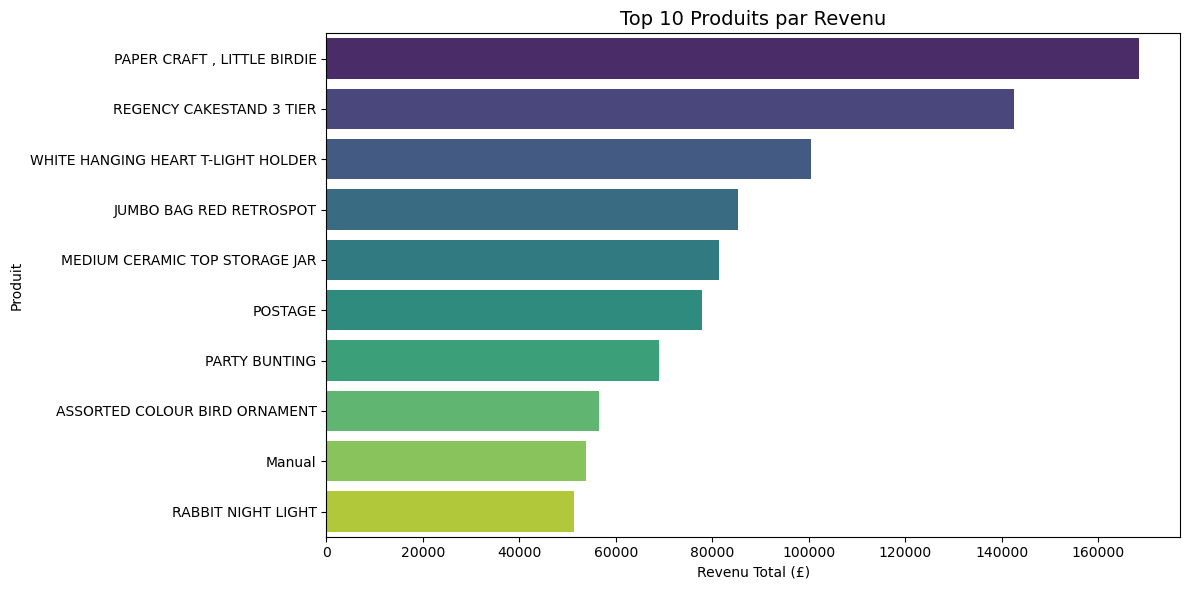

In [4]:
# top 10 produits par revenu total 
top_produits = df.groupby('Description')['TotalPrice'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_produits.values, y=top_produits.index, palette='viridis')
plt.title('Top 10 Produits par Revenu', fontsize=14)
plt.xlabel('Revenu Total (£)')
plt.ylabel('Produit')
plt.tight_layout()
plt.show()

## 4. Revenus par Mois
Évolution du chiffre d'affaires mois par mois.
> Note : La baisse de Décembre 2011 est due à des données incomplètes (dataset arrêté le 9 décembre).

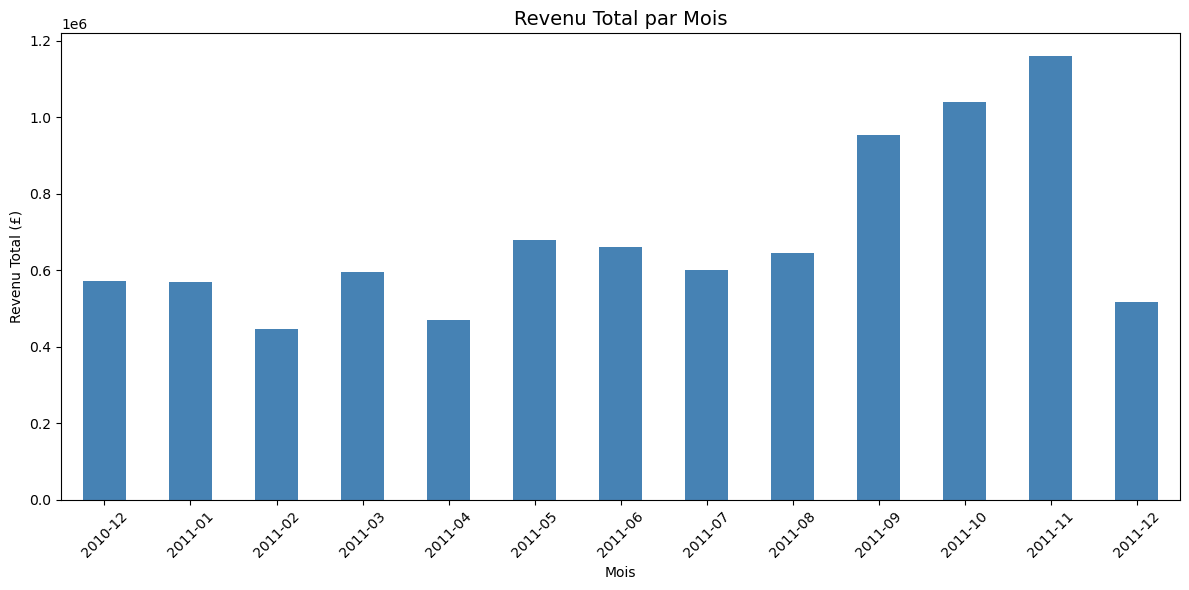

In [5]:
# extraire le mois de la date
df['Month'] = df['InvoiceDate'].dt.to_period('M')

# revenu total par mois
revenu_mensuel = df.groupby('Month')['TotalPrice'].sum()

plt.figure(figsize=(12,6))
revenu_mensuel.plot(kind='bar', color='steelblue')
plt.title('Revenu Total par Mois', fontsize=14)
plt.xlabel('Mois')
plt.ylabel('Revenu Total (£)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 5. Top Pays par Revenu
Le Royaume-Uni représente la grande majorité du revenu (entreprise britannique).
Le graphique exclut le UK pour mieux visualiser la distribution internationale.

Top 10 pays (avec UK):
Country
United Kingdom    7308391.554
Netherlands        285446.340
EIRE               265545.900
Germany            228867.140
France             209024.050
Australia          138521.310
Spain               61577.110
Switzerland         56443.950
Belgium             41196.340
Sweden              38378.330
Name: TotalPrice, dtype: float64


C:\Users\Yassine\AppData\Local\Temp\ipykernel_32832\1450956205.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_pays_sans_uk.values, y=top_pays_sans_uk.index, palette='magma')


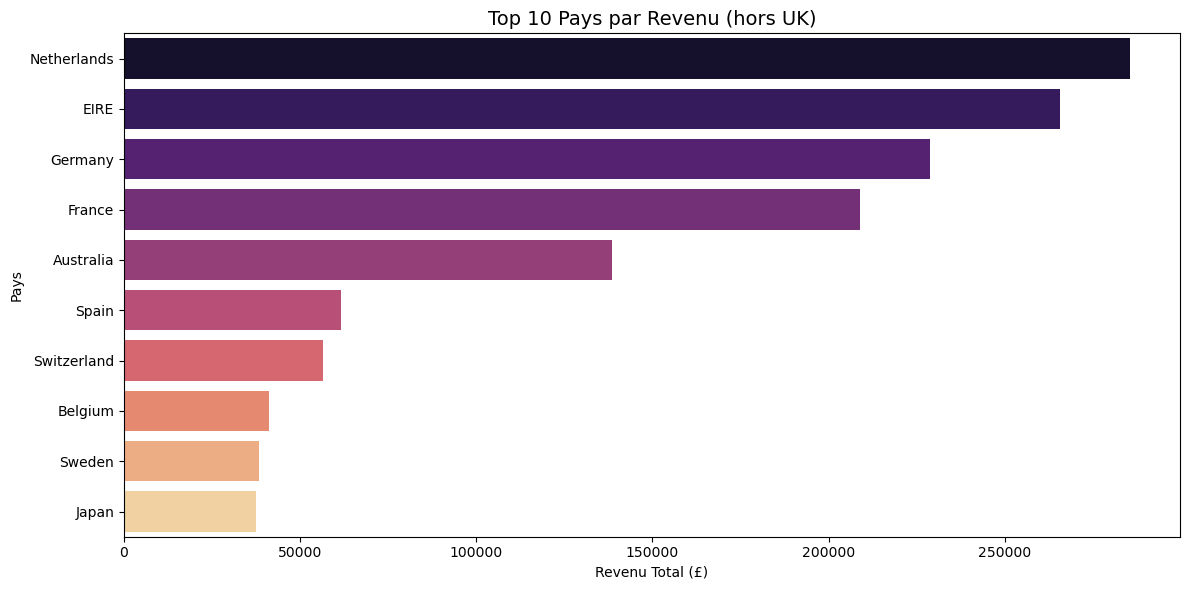

In [6]:
# top 10 pays par revenu (hors UK pour mieux voir les autres)
revenu_pays = df.groupby('Country')['TotalPrice'].sum().sort_values(ascending=False)

print("Top 10 pays (avec UK):")
print(revenu_pays.head(10))

# Graphique sans UK pour mieux void la distribution des autres pays
top_pays_sans_uk = revenu_pays.drop('United Kingdom').head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_pays_sans_uk.values, y=top_pays_sans_uk.index, palette='magma')
plt.title('Top 10 Pays par Revenu (hors UK)', fontsize=14)
plt.xlabel('Revenu Total (£)')
plt.ylabel('Pays')
plt.tight_layout()
plt.show()

## 6. Ventes par Heure de la Journée
À quelle heure les commandes sont-elles passées ?
> Le pic entre 10h-15h confirme un profil B2B (commandes pendant les heures de bureau).

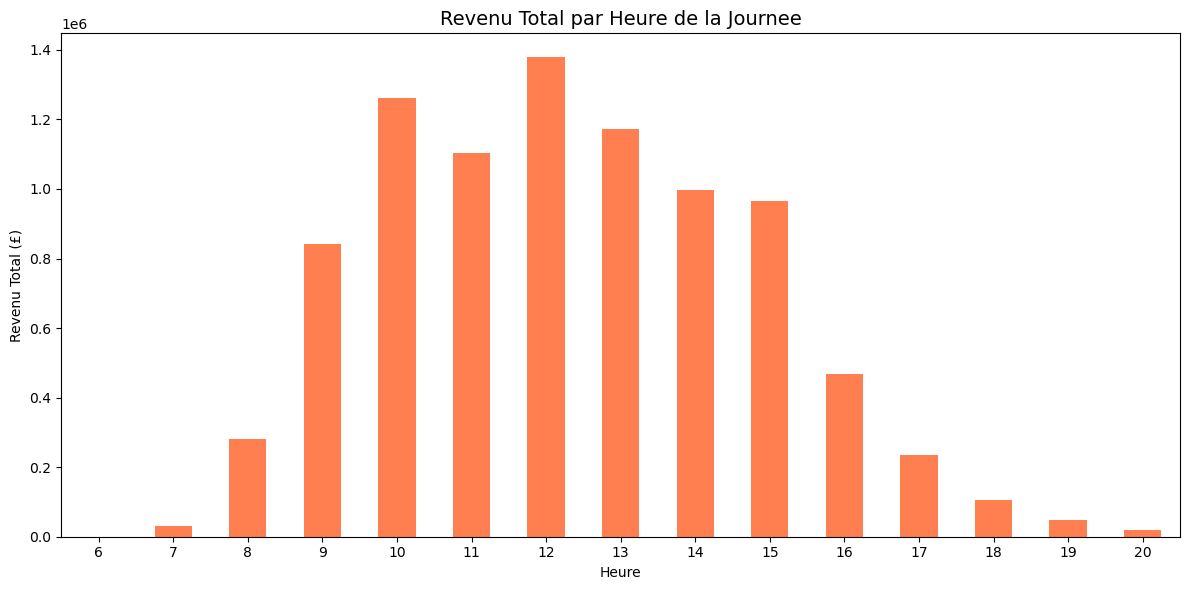

Hour
6           4.250
7       31059.210
8      282115.630
9      842605.171
10    1261192.571
11    1104558.750
12    1378571.480
13    1173264.750
14     995629.371
15     966191.750
16     468885.800
17     234413.521
18     104954.430
19      49028.460
20      18932.760
Name: TotalPrice, dtype: float64


In [7]:
# Extraire l'heur de la commande 
df['Hour'] = df['InvoiceDate'].dt.hour

# Nombre de commandes par heure
ventes_horaires = df.groupby('Hour')['TotalPrice'].sum()

plt.figure(figsize=(12, 6))
ventes_horaires.plot(kind='bar', color='coral')
plt.title('Revenu Total par Heure de la Journee', fontsize=14)
plt.xlabel('Heure')
plt.ylabel('Revenu Total (£)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(ventes_horaires)

## Conclusion
- **Produit star :** PAPER CRAFT, LITTLE BIRDIE avec 168 469£ de revenu
- **Mois le plus rentable :** Novembre 2011 (~1.16M£) — effet fêtes de fin d'année
- **Marché principal :** Royaume-Uni (7.3M£), suivi des Pays-Bas et de l'Irlande
- **Heure de pointe :** 12h avec 1.37M£ de revenu — profil B2B confirmé